# Quantum Portfolio Optimization Using QAOA

**Qiskit Fall Fest 2026 — Track 2: Quantum Optimization**

This notebook documents the six-stock portfolio optimization experiment,
classical exact baseline, QAOA depth and penalty sweeps, and Q-Repair
classical post-processing.

## Research questions

1. Can the six-stock portfolio objective be mapped to a QAOA cost function?
2. How do circuit depth and penalty strength affect feasibility and objective cost?
3. Can a constraint-aware classical repair rule improve the distribution of
   feasible portfolio candidates?
4. How sensitive are the observed results to optimizer initialization?

**Scope:** The QAOA experiments use a six-qubit statevector simulation.
The 12-stock result is a separate classical baseline; no completed
12-stock QAOA result is claimed.

## 1. Mathematical formulation

For a binary portfolio vector \(x\in\{0,1\}^n\), minimize

\[
C(x)=q x^T\Sigma x-\mu^T x+
\lambda\left(\sum_i x_i-K\right)^2.
\]

Here, \(\mu\) contains expected returns, \(\Sigma\) is a positive
semidefinite covariance-like matrix, \(q\) weights risk, and \(K\) is
the required portfolio size. The penalty discourages selecting a number
of stocks other than \(K\).

The experiments use a deterministic synthetic dataset with seed 2026,
six stocks, exactly three selections, and \(q=0.5\).

In [1]:
import itertools
import runpy
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src").is_dir():
    ROOT = ROOT.parent

if not (ROOT / "src").is_dir():
    raise RuntimeError(
        "Cannot find project root. Open this notebook from "
        "E:/Qiskit-Fall-Fest or a subfolder of that directory."
    )

sys.path.insert(0, str(ROOT / "src"))
print("Project root:", ROOT)
print("Python:", sys.version)

Project root: E:\Qiskit-Fall-Fest
Python: 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]


## 2. Reproduce the exact six-stock classical baseline

All \(2^6=64\) binary portfolios are considered, of which
\(\binom{6}{3}=20\) satisfy the exact-three-stock constraint.
The best feasible portfolio is the reference optimum.

In [2]:
rng = np.random.default_rng(2026)
n, K, q = 6, 3, 0.5
mu = rng.uniform(0.05, 0.25, n)
A = rng.normal(0, 0.1, (n, n))
sigma = A @ A.T

bitstrings = np.array(
    list(itertools.product([0, 1], repeat=n)), dtype=int
)

def portfolio_cost(x):
    return float(q * (x @ sigma @ x) - mu @ x)

base_costs = np.array([portfolio_cost(x) for x in bitstrings])
feasible_mask = bitstrings.sum(axis=1) == K
best_idx = np.argmin(np.where(feasible_mask, base_costs, np.inf))
best_x = bitstrings[best_idx]
best_cost = base_costs[best_idx]

print("Total binary portfolios:", len(bitstrings))
print("Feasible portfolios:", int(feasible_mask.sum()))
print("Optimal bitstring:", "".join(map(str, best_x)))
print("Selected stocks (1-based):",
      tuple(np.flatnonzero(best_x) + 1))
print(f"Exact feasible objective: {best_cost:.6f}")

assert len(bitstrings) == 64
assert feasible_mask.sum() == 20
assert tuple(np.flatnonzero(best_x) + 1) == (2, 3, 6)
assert np.isclose(best_cost, -0.503015, atol=1e-5)

Total binary portfolios: 64
Feasible portfolios: 20
Optimal bitstring: 011001
Selected stocks (1-based): (np.int64(2), np.int64(3), np.int64(6))
Exact feasible objective: -0.503015


## 3. Run the QAOA depth experiment

The script uses direct statevector cost-phase and transverse-field mixer
operations. The depth sweep uses a finite COBYLA optimization budget.
Optimizer success flags and evaluation limits must be retained when
interpreting the results.

In [3]:
print("Running six-stock QAOA depth sweep...")
runpy.run_path(str(ROOT / "src" / "qaoa_six_stock.py"),
               run_name="__main__")

depth_csv = ROOT / "results" / "qaoa_depth_sweep.csv"
if depth_csv.exists():
    depth_df = pd.read_csv(depth_csv)
    display(depth_df)
else:
    print("Depth CSV was not created; inspect the script output.")

Running six-stock QAOA depth sweep...


Exact classical optimum: (np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(1))
Exact classical cost: -0.503015

=== QAOA depth sweep ===


p=1 | expected cost=0.110713 | feasible=57.90% | exact optimum=3.68% | evals=49 | runtime=0.32s


p=2 | expected cost=0.202474 | feasible=67.94% | exact optimum=3.38% | evals=100 | runtime=0.34s


p=3 | expected cost=-0.101954 | feasible=92.69% | exact optimum=5.03% | evals=100 | runtime=0.59s


p=4 | expected cost=-0.213192 | feasible=88.23% | exact optimum=4.55% | evals=100 | runtime=0.53s

Saved results/qaoa_depth_sweep.npz
QAOA DEPTH SWEEP FINISHED


,p,expected_cost,feasible_probability,exact_optimum_probability
0,1,0.110713,0.579032,0.036819
1,2,0.202474,0.679362,0.033783
2,3,-0.101954,0.926896,0.050307
3,4,-0.213192,0.882348,0.045502


qaoa_probabilities.png


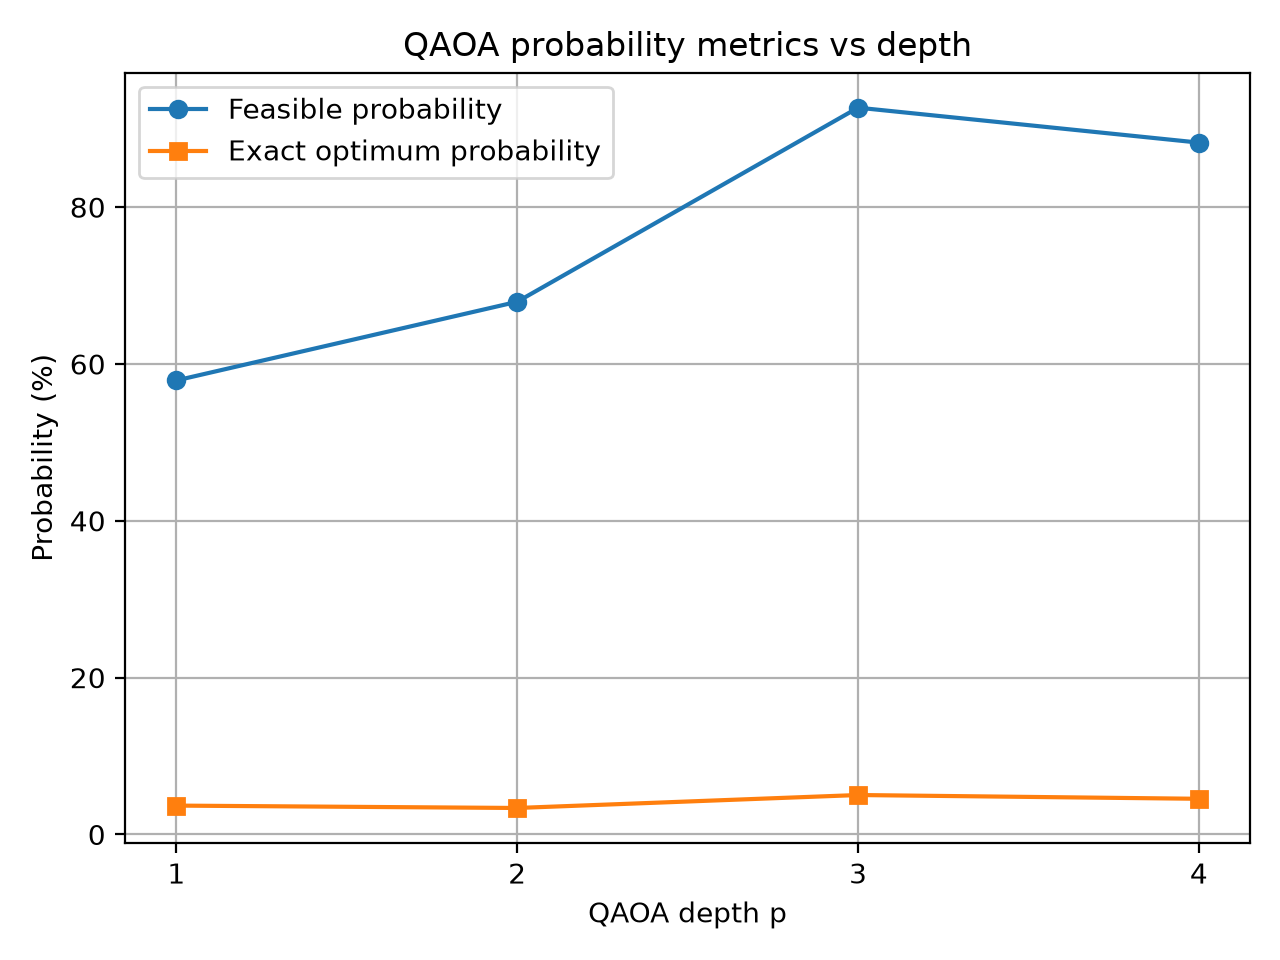

qaoa_expected_cost.png


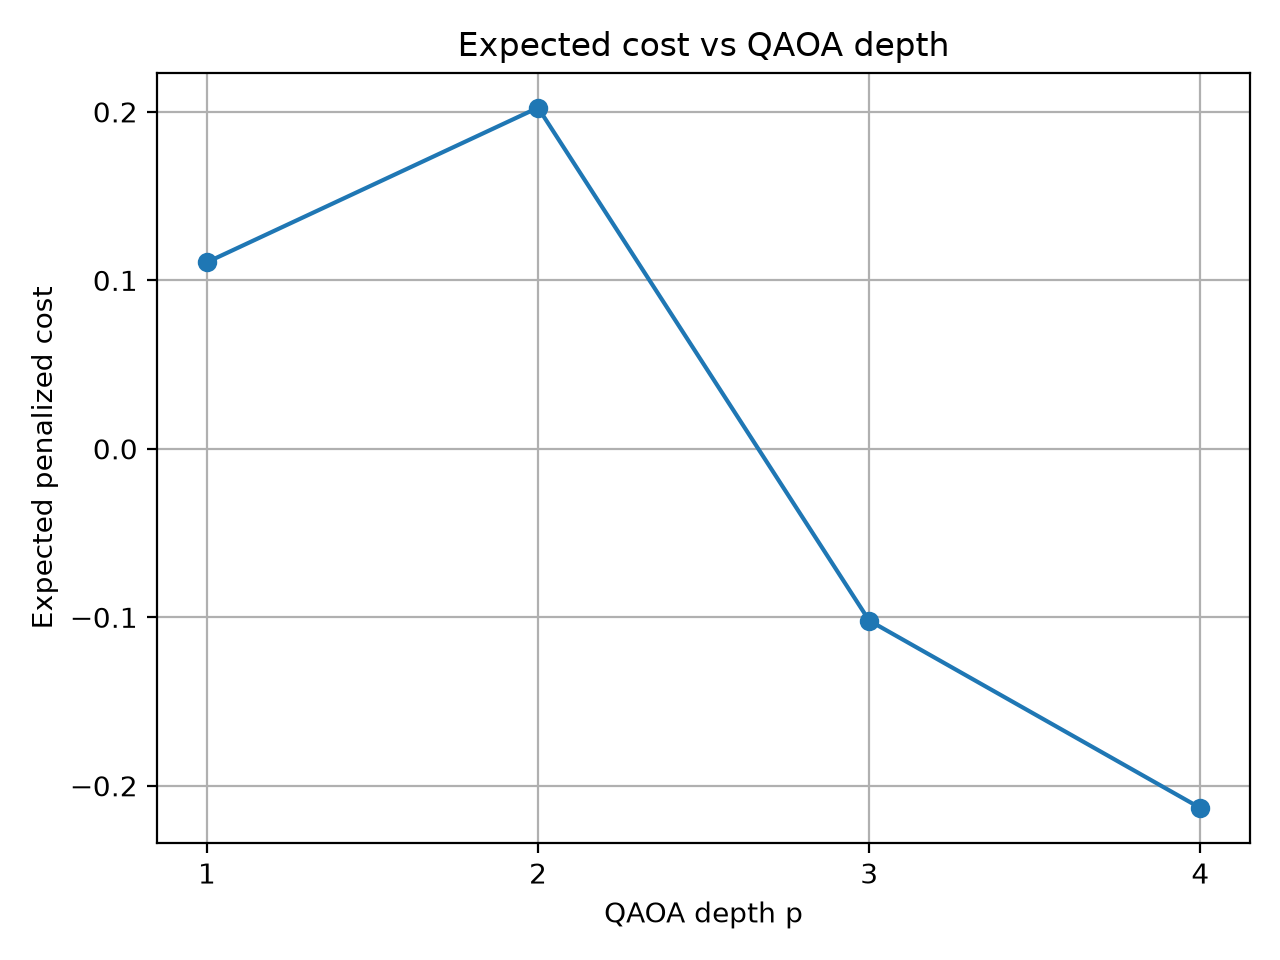

In [4]:
for filename in [
    "qaoa_probabilities.png",
    "qaoa_expected_cost.png",
]:
    path = ROOT / "plots" / filename
    if path.exists():
        print(filename)
        display(Image(filename=str(path)))
    else:
        print("Plot not found:", path)

## 4. Penalty-strength sweep

The penalty parameter controls how strongly infeasible portfolios are
discouraged. Feasibility probability and exact-optimum probability are
different metrics; the best penalty can depend on which metric matters.

Running penalty sweep...


lambda=0.01 | feasible=3.88% | exact optimum=1.41% | expected cost=-0.62771 | time=0.16s


lambda=0.05 | feasible=26.34% | exact optimum=2.17% | expected cost=-0.44152 | time=0.17s


lambda= 0.1 | feasible=47.38% | exact optimum=2.91% | expected cost=-0.37640 | time=0.19s


lambda=0.25 | feasible=62.35% | exact optimum=2.75% | expected cost=-0.24652 | time=0.16s


...

lambda= 1.0 | feasible=57.90% | exact optimum=3.68% | expected cost=0.11071 | time=0.36s


lambda= 2.0 | feasible=67.05% | exact optimum=3.30% | expected cost=0.38683 | time=0.25s


lambda= 5.0 | feasible=67.10% | exact optimum=3.37% | expected cost=1.52350 | time=0.38s



Saved: E:\Qiskit-Fall-Fest\results\qaoa_penalty_sweep.csv
Saved: E:\Qiskit-Fall-Fest\plots\qaoa_penalty_sweep.png
PENALTY SWEEP FINISHED


,lambda,feasible_probability,exact_optimum_probability,expected_penalized_cost,optimizer_success,runtime_seconds
0,0.01,0.038831,0.014133,-0.627705,False,0.164027
1,0.05,0.263371,0.021698,-0.441516,False,0.166875
2,0.10,0.473786,0.029138,-0.376397,False,0.185104
3,0.25,0.623480,0.027462,-0.246522,False,0.159064
4,0.50,0.661235,0.034483,-0.197522,False,0.328567
5,1.00,0.579032,0.036819,0.110713,True,0.361447
6,2.00,0.670550,0.032974,0.386828,True,0.245278
7,5.00,0.671011,0.033694,1.523501,True,0.381138


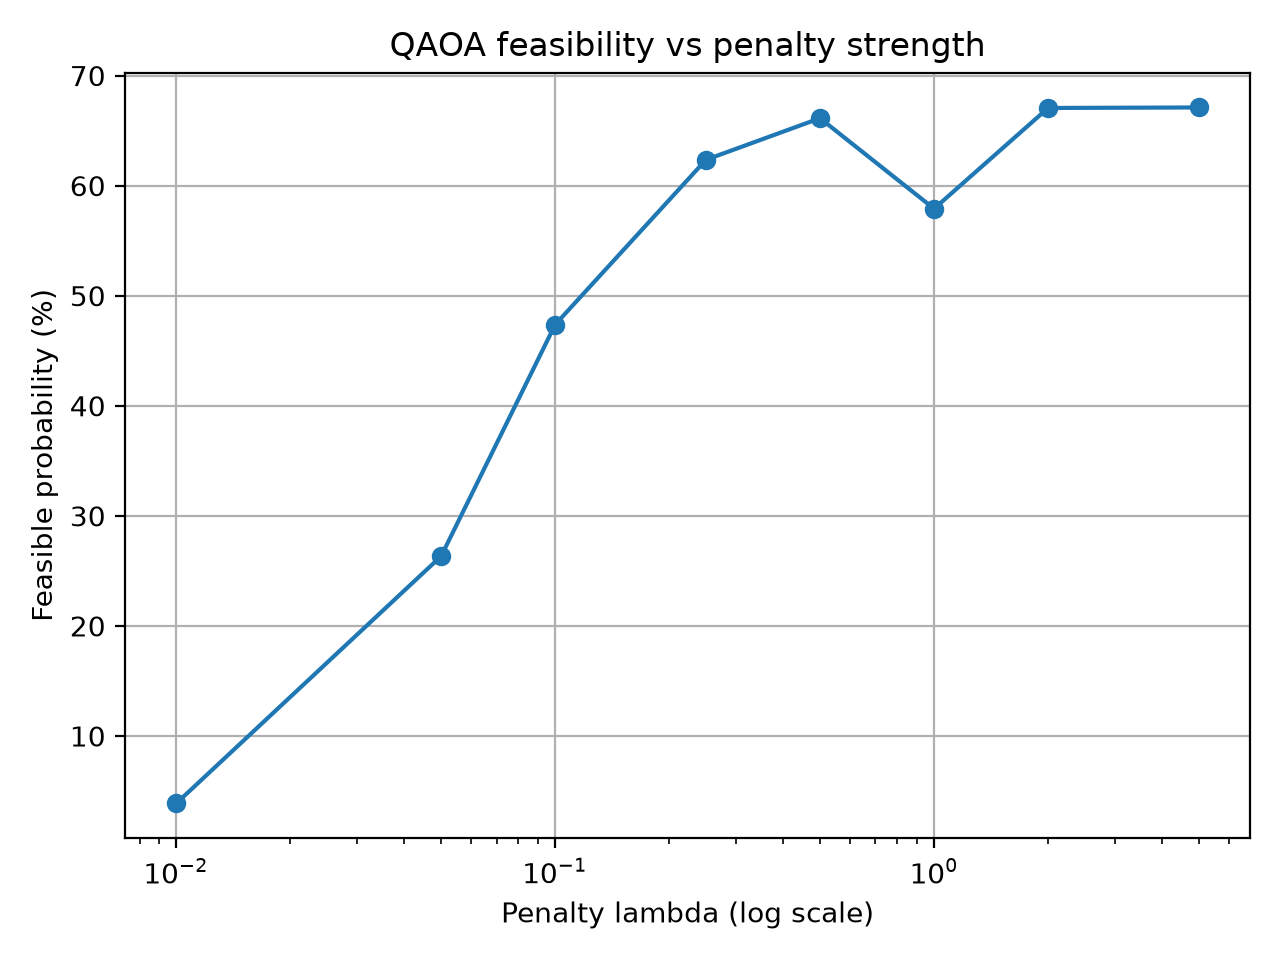

In [5]:
print("Running penalty sweep...")
runpy.run_path(str(ROOT / "src" / "penalty_sweep.py"),
               run_name="__main__")

penalty_csv = ROOT / "results" / "qaoa_penalty_sweep.csv"
if penalty_csv.exists():
    penalty_df = pd.read_csv(penalty_csv)
    display(penalty_df)
else:
    print("Penalty CSV was not created; inspect the script output.")

penalty_plot = ROOT / "plots" / "qaoa_penalty_sweep.png"
if penalty_plot.exists():
    display(Image(filename=str(penalty_plot)))

## 5. Q-Repair: constraint-aware classical post-processing

Q-Repair maps each bitstring to a feasible portfolio by changing the
minimum number of bits needed to select exactly three stocks. Among
equally close candidates, it selects the lowest-cost feasible portfolio.

This is a classical post-processing heuristic, not a quantum speedup.
The repaired optimum probability is probability mass mapped to the
optimum after repair, not the raw probability of measuring that bitstring.

Running Q-Repair and eight-start stability experiment...
=== QAOA INITIALIZATION STABILITY ===


Start 1 | objective=-0.101954 | success=False | evaluations=100


Start 2 | objective=0.275723 | success=False | evaluations=100


Start 3 | objective=0.522604 | success=False | evaluations=100


Start 4 | objective=-0.082343 | success=False | evaluations=100


...

Start 7 | objective=-0.053129 | success=False | evaluations=100


Start 8 | objective=0.066307 | success=False | evaluations=100

=== Q-REPAIR SUMMARY ===
Exact classical optimum: (0, 1, 1, 0, 0, 1)
Exact classical cost: -0.503015
Best run success flag: False
Best run evaluations: 100
Total runtime: 2.85s

--- Raw QAOA distribution ---
Feasible probability: 92.69%
Exact-optimum probability: 5.03%
Conditional feasible cost: -0.382748

--- After Q-Repair ---
Expected original portfolio cost: -0.389191
Exact-optimum probability mass: 8.81%
Most probable repaired portfolio: (0, 1, 1, 0, 0, 1)
Probability of most probable repaired portfolio: 8.81%
Lowest-cost repaired portfolio: (0, 1, 1, 0, 0, 1)
Lowest repaired cost: -0.503015

Saved artifacts:
  E:\Qiskit-Fall-Fest\results\qaoa_initialization_stability.csv
  E:\Qiskit-Fall-Fest\results\q_repair_results.csv
  E:\Qiskit-Fall-Fest\results\q_repair_distribution.npz

Q-REPAIR FINISHED
\n q_repair_results.csv


,p,penalty,num_starts,optimizer_success,optimizer_evaluations,total_runtime_seconds,exact_classical_cost,raw_feasible_probability,raw_exact_optimum_probability,raw_conditional_feasible_cost,repaired_expected_portfolio_cost,repaired_exact_optimum_probability,most_probable_repaired_portfolio,most_probable_repaired_probability,lowest_cost_repaired_portfolio,lowest_repaired_cost
0,3,1.0,8,False,100,2.846899,-0.503015,0.926896,0.050307,-0.382748,-0.389191,0.08809,0-1-1-0-0-1,0.08809,0-1-1-0-0-1,-0.503015


\n qaoa_initialization_stability.csv


,start,objective,success,evaluations
0,1,-0.101954,False,100
1,2,0.275723,False,100
2,3,0.522604,False,100
3,4,-0.082343,False,100
4,5,0.333076,False,100
5,6,0.095500,False,100
6,7,-0.053129,False,100
7,8,0.066307,False,100


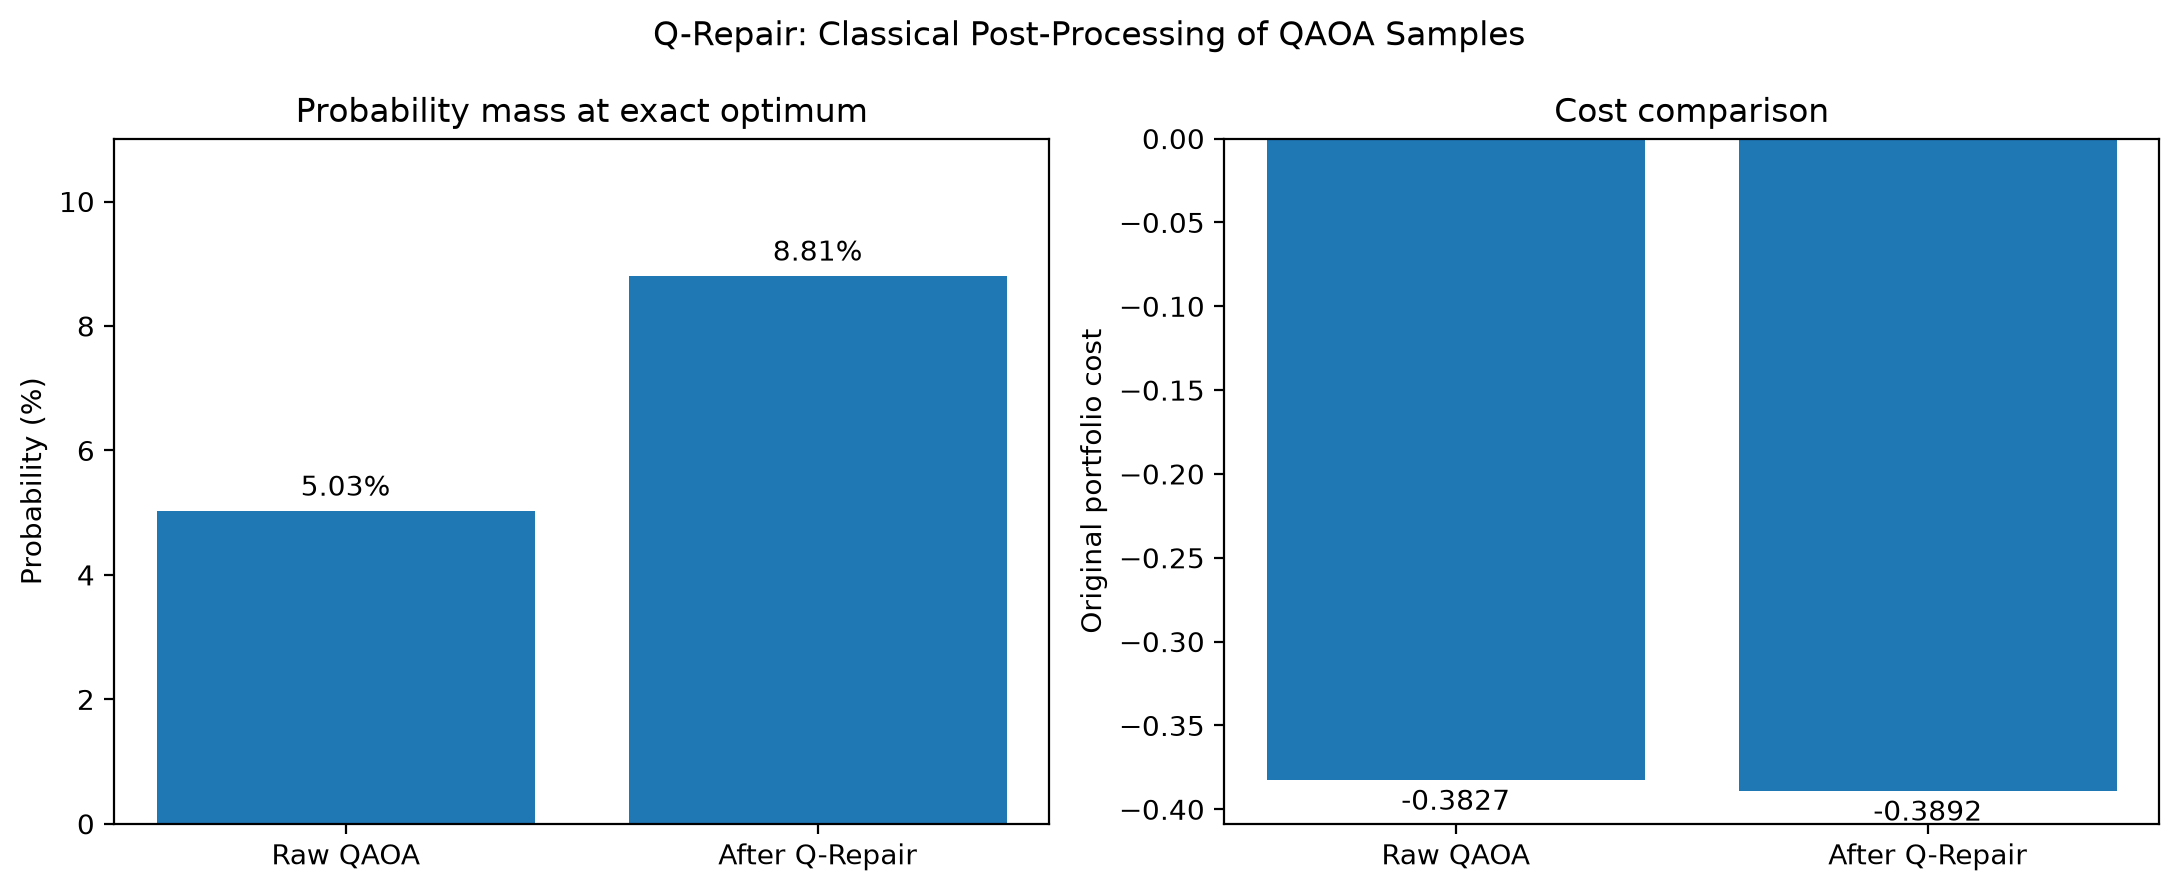

In [6]:
print("Running Q-Repair and eight-start stability experiment...")
runpy.run_path(str(ROOT / "src" / "q_repair.py"),
               run_name="__main__")

for filename in [
    "q_repair_results.csv",
    "qaoa_initialization_stability.csv",
]:
    path = ROOT / "results" / filename
    if path.exists():
        print("\\n", filename)
        display(pd.read_csv(path))
    else:
        print("Result file not found:", path)

repair_plot = ROOT / "plots" / "q_repair_comparison.png"
if repair_plot.exists():
    display(Image(filename=str(repair_plot)))

## 6. Intermediate track: 12-stock classical baseline

For twelve stocks and six required selections, exhaustive search considers

\[
\binom{12}{6}=924
\]

feasible portfolios. The separate classical experiment reported the
best portfolio as one-based stocks 2, 6, 7, 9, 11, and 12, with objective
approximately -1.066392.

This is a classical result only. This notebook does not claim a completed
12-stock QAOA experiment.

## 7. Results interpretation

- The exact six-stock baseline is the reference optimum for this synthetic instance.
- QAOA performance is sensitive to depth, penalty strength, and initialization.
- The reported depth and penalty sweeps use finite optimizer budgets.
- All eight reported stability runs reached the configured evaluation limit
  with `success=False`; convergence is not established.
- Q-Repair increases the observed probability mass mapped to the exact optimum
  from 5.03% to 8.81% for the selected run, but uses the known objective
  function as part of classical repair.
- Simulation results do not establish quantum advantage over classical methods.

## 8. Reproducibility and artifacts

The source scripts are in `src/`, numerical data in `results/`, and plots in
`plots/`. The synthetic data uses NumPy seed 2026. Optimizer results may depend
on library versions, settings, and initialization.

For submission, ensure the notebook runs from top to bottom in a clean
environment, then save it with its outputs if required by the event rules.